<a href="https://colab.research.google.com/github/vishwa24816/Hourly-return-backtester/blob/main/Hourly%20return%20backtester.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from datetime import date, timedelta

In [6]:
TICKER = 'AAPL'
BASE_INTERVAL = '60m'           # yfinance's finest interval for ~2 years of history
INTERVAL_SECONDS = 3600         # 1-hour slots (must be a multiple of 3600)
LOOKBACK_DAYS = 729             # yfinance limit for 60m data (about 2 years)
MARKET_OPEN_SEC = 9 * 3600 + 30 * 60
MARKET_CLOSE_SEC = 16 * 3600
TOP_N = 3

assert INTERVAL_SECONDS % 3600 == 0, 'INTERVAL_SECONDS must be a multiple of 3600 for 60m base data'
print(f'Ticker: {TICKER} | Base: {BASE_INTERVAL} | Slot: {INTERVAL_SECONDS} s | Lookback: {LOOKBACK_DAYS} days')

Ticker: AAPL | Base: 60m | Slot: 3600 s | Lookback: 729 days


In [7]:
def fetch_intraday(ticker, lookback_days, interval):
    end = date.today() + timedelta(days=1)
    start = date.today() - timedelta(days=lookback_days)
    df = yf.download(ticker, start=str(start), end=str(end), interval=interval,
                     auto_adjust=True, progress=False)
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.get_level_values(0)
    df = df[['Open', 'High', 'Low', 'Close', 'Volume']].dropna()
    if df.index.tz is None:
        df.index = df.index.tz_localize('America/New_York')
    else:
        df.index = df.index.tz_convert('America/New_York')
    sec_of_day = (df.index - df.index.normalize()).total_seconds()
    return df[(sec_of_day >= MARKET_OPEN_SEC) & (sec_of_day < MARKET_CLOSE_SEC)]

raw = fetch_intraday(TICKER, LOOKBACK_DAYS, BASE_INTERVAL)
print(f'{len(raw):,} bars from {raw.index[0]} to {raw.index[-1]}')
raw.tail()

3,471 bars from 2024-10-31 09:30:00-04:00 to 2026-10-29 15:30:00-04:00


Price,Open,High,Low,Close,Volume
Datetime,,,,,
2026-10-29 11:30:00-04:00,348.915009,349.609985,348.660004,349.465088,2219884
2026-10-29 12:30:00-04:00,349.464996,350.129913,349.070007,349.779999,2468751
2026-10-29 13:30:00-04:00,349.790009,350.149994,349.320007,349.875000,2519513
2026-10-29 14:30:00-04:00,349.869995,350.600006,349.779999,350.390015,2827795
2026-10-29 15:30:00-04:00,350.383087,350.440002,348.299988,348.940002,5011327


In [8]:
def build_bars(df, seconds):
    sec_of_day = (df.index - df.index.normalize()).total_seconds()
    d = df.copy()
    d['session'] = df.index.date
    d['slot_sec'] = (np.floor((sec_of_day - MARKET_OPEN_SEC) / seconds) * seconds).astype(int)
    g = d.groupby(['session', 'slot_sec'])
    bars = pd.DataFrame({
        'Open': g['Open'].first(), 'High': g['High'].max(),
        'Low': g['Low'].min(), 'Close': g['Close'].last(),
        'Volume': g['Volume'].sum(),
    }).reset_index().sort_values(['session', 'slot_sec']).reset_index(drop=True)
    prev_close = bars.groupby('session')['Close'].shift(1).fillna(bars['Open'])
    bars['ret'] = bars['Close'] / prev_close - 1
    return bars

def slot_label(sec_after_open):
    t = MARKET_OPEN_SEC + int(sec_after_open)
    return f'{t // 3600:02d}:{(t % 3600) // 60:02d}'

bars = build_bars(raw, INTERVAL_SECONDS)
bars['slot'] = bars['slot_sec'].map(slot_label)
print(f"{bars['session'].nunique()} sessions, {len(bars)} bars, {bars['slot'].nunique()} slots")
bars.head()

500 sessions, 3471 bars, 7 slots


,session,slot_sec,Open,High,Low,Close,Volume,ret,slot
0,2024-10-31,0,229.229996,229.830002,227.809998,228.445007,9145169,-0.003424,09:30
1,2024-10-31,3600,228.449997,228.729996,226.880005,227.315002,5587159,-0.004947,10:30
2,2024-10-31,7200,227.309998,227.485001,226.410004,227.250000,3752999,-0.000286,11:30
3,2024-10-31,10800,227.279999,228.176804,227.200195,227.860107,3450859,0.002685,12:30
4,2024-10-31,14400,227.860001,227.966293,226.824997,227.089996,3797245,-0.003380,13:30


In [9]:
stats = bars.groupby('slot_sec').agg(
    slot=('slot', 'first'),
    n=('ret', 'size'),
    mean_bps=('ret', lambda x: x.mean() * 1e4),
    avg_up_bps=('ret', lambda x: x[x > 0].mean() * 1e4),
    avg_down_bps=('ret', lambda x: x[x < 0].mean() * 1e4),
    up_rate_pct=('ret', lambda x: (x > 0).mean() * 100),
).reset_index()

stats.round(2)

,slot_sec,slot,n,mean_bps,avg_up_bps,avg_down_bps,up_rate_pct
0,0,09:30,499,10.18,74.39,-68.65,55.11
1,3600,10:30,499,-1.12,40.17,-41.93,49.50
2,7200,11:30,498,-0.35,32.33,-28.97,46.59
3,10800,12:30,493,0.20,30.13,-30.35,50.30
4,14400,13:30,494,0.25,25.23,-25.88,51.01
5,18000,14:30,494,-0.29,25.58,-26.80,50.61
6,21600,15:30,494,2.80,27.52,-24.79,52.63


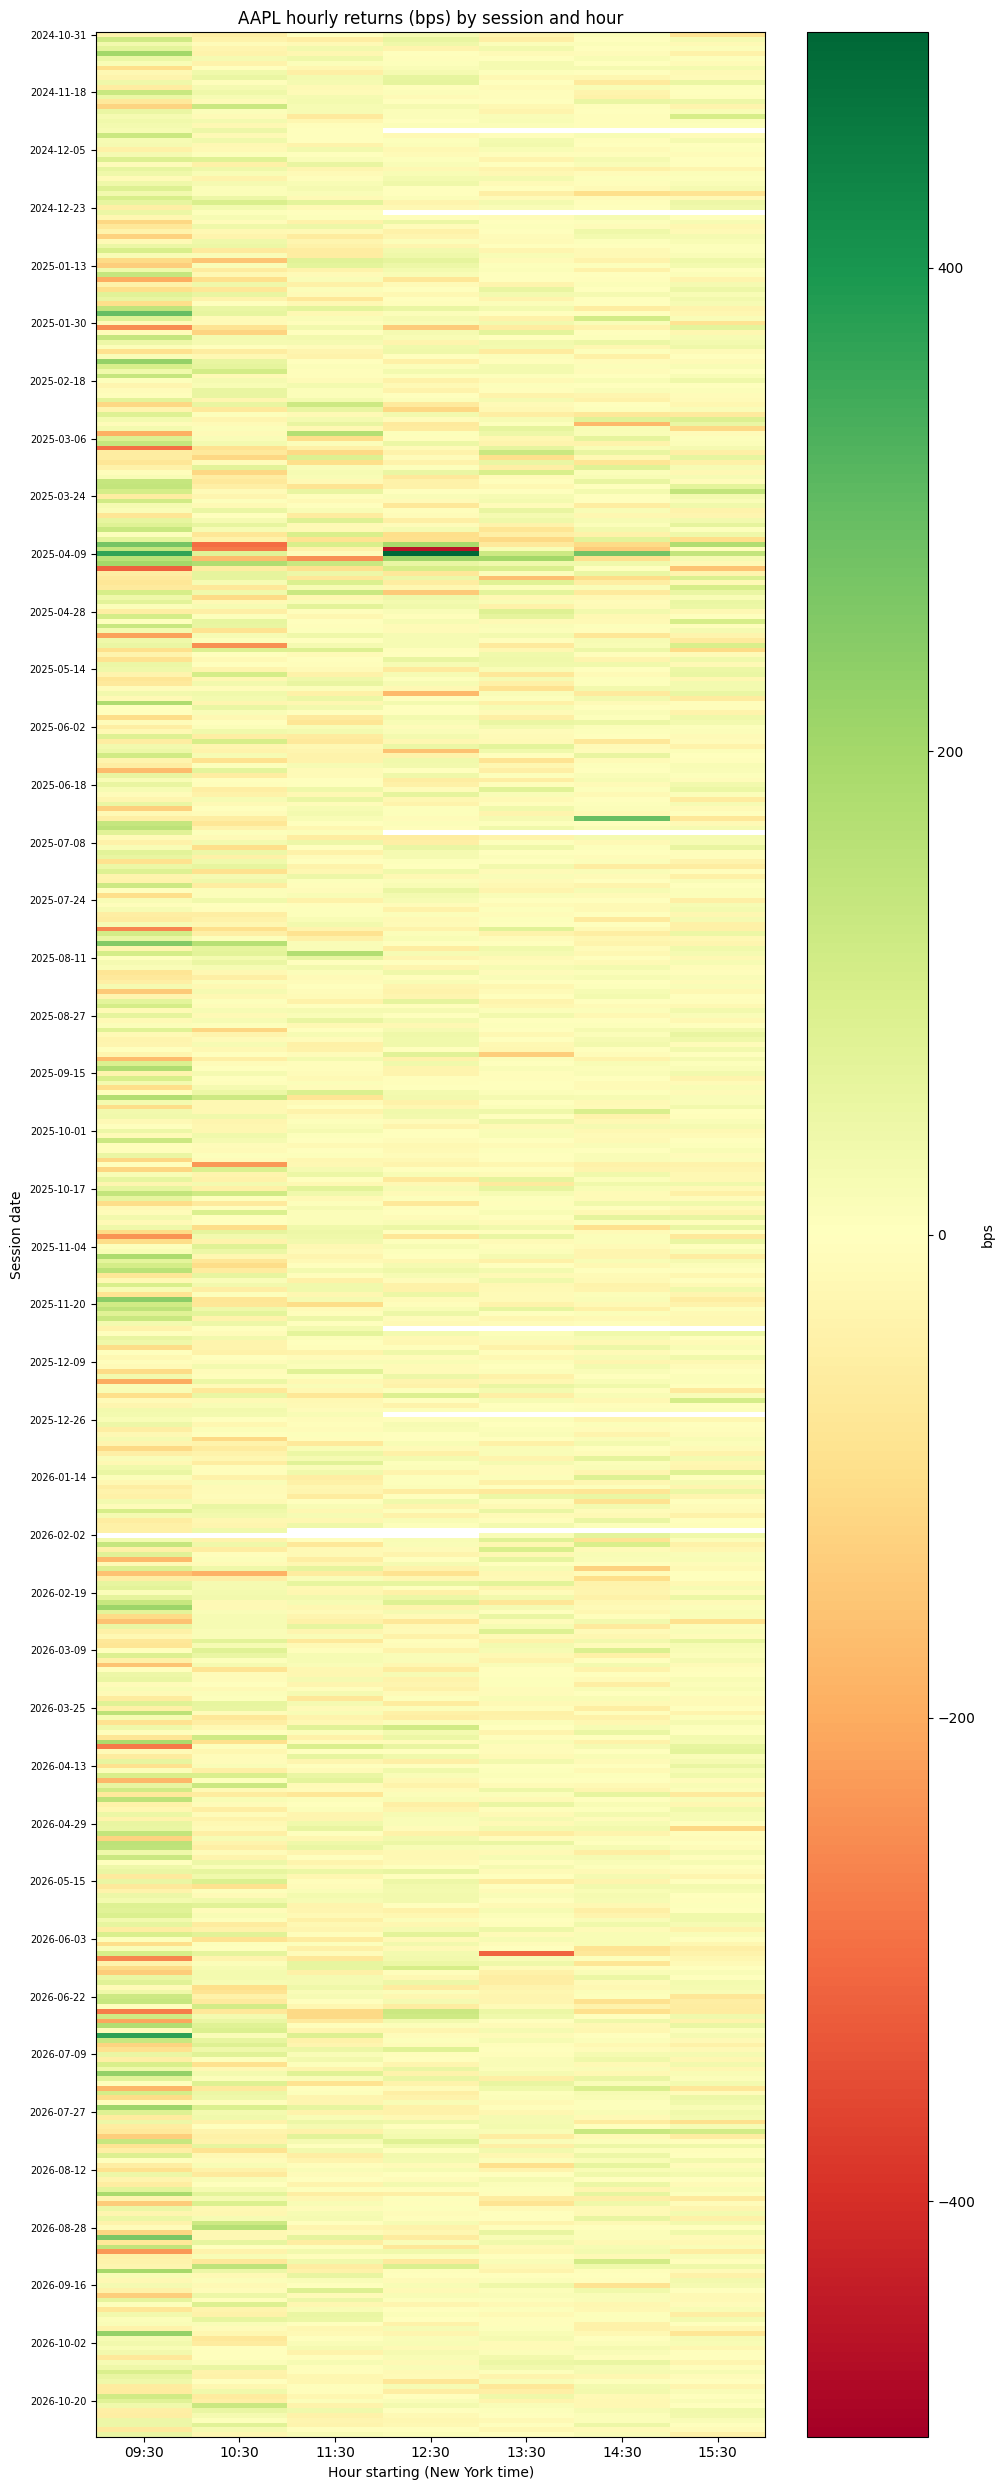

In [10]:
pivot = bars.pivot(index='session', columns='slot_sec', values='ret') * 1e4
lim = np.nanmax(np.abs(pivot.values))
step = max(1, len(pivot) // 40)     # thin out date labels for ~500 sessions

fig, ax = plt.subplots(figsize=(10, min(30, max(5, 0.05 * len(pivot)))))
im = ax.imshow(pivot.values, aspect='auto', cmap='RdYlGn', vmin=-lim, vmax=lim)
ax.set_xticks(range(len(pivot.columns)))
ax.set_xticklabels([slot_label(s) for s in pivot.columns])
ax.set_yticks(range(0, len(pivot.index), step))
ax.set_yticklabels([str(d) for d in pivot.index[::step]], fontsize=7)
ax.set_xlabel('Hour starting (New York time)')
ax.set_ylabel('Session date')
ax.set_title(f'{TICKER} hourly returns (bps) by session and hour')
plt.colorbar(im, ax=ax, label='bps')
plt.tight_layout()
plt.show()

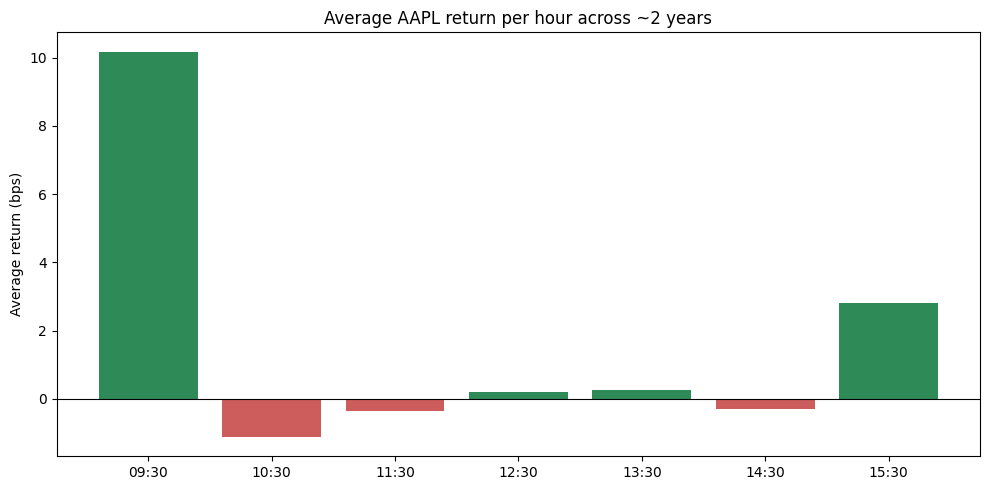

In [11]:
colors = np.where(stats['mean_bps'] >= 0, 'seagreen', 'indianred')

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(stats['slot'], stats['mean_bps'], color=colors)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_ylabel('Average return (bps)')
ax.set_title(f'Average {TICKER} return per hour across ~2 years')
plt.tight_layout()
plt.show()

In [12]:
R = bars.pivot(index='session', columns='slot_sec', values='ret').fillna(0)

# expanding mean uses only prior sessions, so there is no lookahead
hist_mean = R.shift(1).expanding(min_periods=5).mean()
position = np.sign(hist_mean).fillna(0)      # +1 long, -1 short, 0 flat

strat_daily = (1 + position * R).prod(axis=1) - 1

day = bars.groupby('session').agg(o=('Open', 'first'), c=('Close', 'last'))
bh_daily = day['c'] / day['o'] - 1

WARMUP = 5
strat_daily = strat_daily.iloc[WARMUP:]
bh_daily = bh_daily.iloc[WARMUP:]
print(f'Backtest sessions after warm-up: {len(strat_daily)} (no transaction costs)')

Backtest sessions after warm-up: 495 (no transaction costs)


               Total return %  Ann. Sharpe  Max drawdown %  Session hit rate %
Slot strategy            18.4         0.49          -22.99               52.32
Buy & hold               68.3         1.21          -18.35               54.14


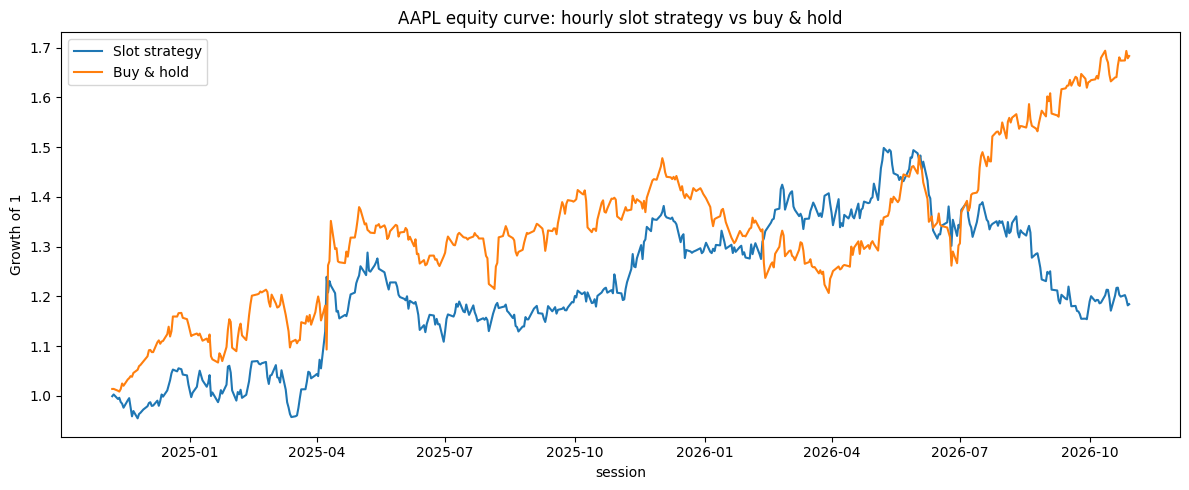

In [13]:
def metrics(r):
    eq = (1 + r).cumprod()
    dd = eq / eq.cummax() - 1
    sharpe = np.sqrt(252) * r.mean() / r.std() if r.std() > 0 else np.nan
    return {
        'Total return %': (eq.iloc[-1] - 1) * 100,
        'Ann. Sharpe': sharpe,
        'Max drawdown %': dd.min() * 100,
        'Session hit rate %': (r > 0).mean() * 100,
    }

results = pd.DataFrame({
    'Slot strategy': metrics(strat_daily),
    'Buy & hold': metrics(bh_daily),
}).T
print(results.round(2))

fig, ax = plt.subplots(figsize=(12, 5))
(1 + strat_daily).cumprod().plot(ax=ax, label='Slot strategy')
(1 + bh_daily).cumprod().plot(ax=ax, label='Buy & hold')
ax.set_title(f'{TICKER} equity curve: hourly slot strategy vs buy & hold')
ax.set_ylabel('Growth of 1')
ax.legend()
plt.tight_layout()
plt.show()

In [14]:
top_pos = stats.nlargest(TOP_N, 'mean_bps')[['slot', 'mean_bps', 'up_rate_pct', 'n']]
top_neg = stats.nsmallest(TOP_N, 'mean_bps')[['slot', 'mean_bps', 'up_rate_pct', 'n']]

print(f'Top {TOP_N} hours by average return:')
display(top_pos.round(2))
print(f'Bottom {TOP_N} hours by average return:')
display(top_neg.round(2))

Top 3 hours by average return:


,slot,mean_bps,up_rate_pct,n
0,09:30,10.18,55.11,499
6,15:30,2.80,52.63,494
4,13:30,0.25,51.01,494


Bottom 3 hours by average return:


,slot,mean_bps,up_rate_pct,n
1,10:30,-1.12,49.50,499
2,11:30,-0.35,46.59,498
5,14:30,-0.29,50.61,494


,slot,n,mean_bps,std_ret,sharpe_ann
0,09:30,499,10.1820,0.0095,1.7103
6,15:30,494,2.7963,0.0036,1.2364
4,13:30,494,0.2483,0.0038,0.1051
3,12:30,493,0.2005,0.0049,0.0645
5,14:30,494,-0.2946,0.0040,-0.1181
2,11:30,498,-0.3535,0.0041,-0.1356
1,10:30,499,-1.1229,0.0056,-0.3184


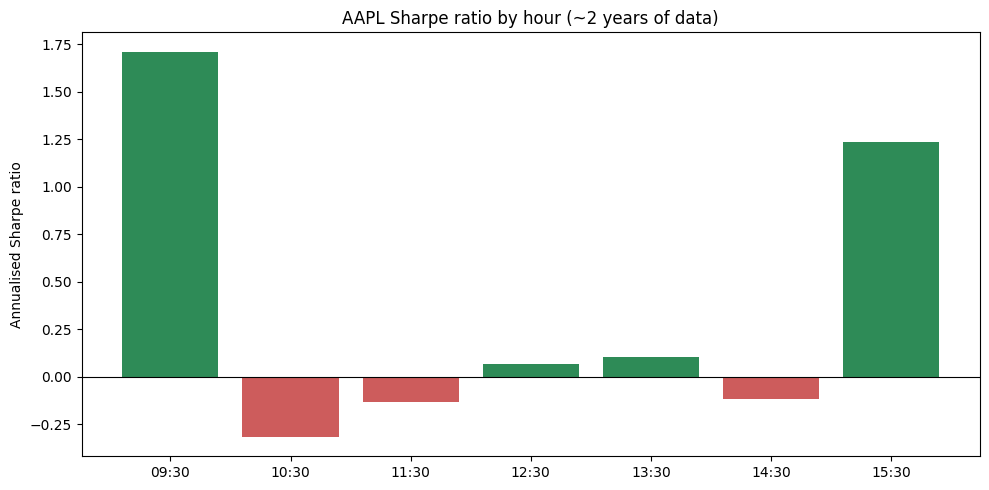

In [15]:
RISK_FREE_ANNUAL = 0.0          # set to the current annual risk-free rate if you want excess returns
BARS_PER_YEAR = 252 * (len(stats))   # approx. number of slots per year (sessions per year x slots per session)

rf_per_bar = RISK_FREE_ANNUAL / BARS_PER_YEAR

sharpe_by_slot = bars.groupby('slot_sec').agg(
    slot=('slot', 'first'),
    n=('ret', 'size'),
    mean_ret=('ret', 'mean'),
    std_ret=('ret', 'std'),
).reset_index()

sharpe_by_slot['excess_mean'] = sharpe_by_slot['mean_ret'] - rf_per_bar
sharpe_by_slot['sharpe_ann'] = (
    sharpe_by_slot['excess_mean'] / sharpe_by_slot['std_ret'] * np.sqrt(252)
)
sharpe_by_slot['mean_bps'] = sharpe_by_slot['mean_ret'] * 1e4

sharpe_by_slot = sharpe_by_slot[['slot', 'n', 'mean_bps', 'std_ret', 'sharpe_ann']]
display(sharpe_by_slot.sort_values('sharpe_ann', ascending=False).round(4))

fig, ax = plt.subplots(figsize=(10, 5))
colors = np.where(sharpe_by_slot['sharpe_ann'] >= 0, 'seagreen', 'indianred')
ax.bar(sharpe_by_slot['slot'], sharpe_by_slot['sharpe_ann'], color=colors)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_ylabel('Annualised Sharpe ratio')
ax.set_title(f'{TICKER} Sharpe ratio by hour (~2 years of data)')
plt.tight_layout()
plt.show()